## Minimize Action

In [ ]:
import torch
import torch.nn as nn
import numpy as np
import matplotlib.pyplot as plt
import time

# ─── Device: MPS (Apple Silicon GPU) ───
if torch.backends.mps.is_available():
    device = torch.device("mps")
    print("✓ Usando GPU Apple Silicon (MPS)")
else:
    device = torch.device("cpu")
    print("⚠ MPS no disponible, usando CPU")

g = -9.81
dt = 0.05
N = 25
m = 1.0

LAMBDA_STATION = 20.0       
LAMBDA_ENERGY  = 100.0       
LAMBDA_IC_VEL  = 50.0    

EPOCHS = 500000
BATCH_SIZE = 2048
LR_INIT = 3e-3
CLIP_NORM = 1.0


x_min, x_max = -15, 15
y_min, y_max = -15, 15
vx_min, vx_max = -15, 15
vy_min, vy_max = -15, 15


✓ Usando GPU Apple Silicon (MPS)


In [ ]:
class ActionNet(nn.Module):
    def __init__(self, n_points=25):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(4, 128),
            nn.SiLU(),
            nn.LayerNorm(128),
            nn.Linear(128, 256),
            nn.SiLU(),
            nn.LayerNorm(256),
            nn.Linear(256, 256),
            nn.SiLU(),
            nn.LayerNorm(256),
            nn.Linear(256, 128),
            nn.SiLU(),
            nn.Linear(128, 2 * n_points),
        )

    def forward(self, x):
        return self.net(x)

model = ActionNet(N).to(device)
print(f"Parámetros: {sum(p.numel() for p in model.parameters()):,}")


Parámetros: 140,082


In [45]:
def compute_interval_lagrangians(pred, batch):
    """
    Calcula el Lagrangiano Lᵢ en cada intervalo [tᵢ, tᵢ₊₁].
    Retorna las cantidades como tensores que MANTIENEN el grafo de autograd
    con respecto a pred.
    """
    x0 = batch[:, 0:1]
    y0 = batch[:, 1:2]

    x_full = torch.cat([x0, pred[:, :N]], dim=1)   # (B, 26)
    y_full = torch.cat([y0, pred[:, N:]], dim=1)

    # Velocidades
    vx = (x_full[:, 1:] - x_full[:, :-1]) / dt     # (B, 25)
    vy = (y_full[:, 1:] - y_full[:, :-1]) / dt

    # Posición en puntos medios
    y_mid = (y_full[:, 1:] + y_full[:, :-1]) / 2.0

    # Lagrangiano por intervalo
    T = 0.5 * m * (vx**2 + vy**2)                   # (B, 25)
    V = m * (-g) * y_mid
    L_i = T - V                                      # (B, 25)

    return L_i, vx, vy, T, V, x_full, y_full

In [ ]:
def compute_action(pred, batch):

    x0  = batch[:, 0:1]
    y0  = batch[:, 1:2]

    x_full = torch.cat([x0, pred[:, :N]], dim=1)   # (B, 26)
    y_full = torch.cat([y0, pred[:, N:]], dim=1)

    vx = (x_full[:, 1:] - x_full[:, :-1]) / dt
    vy = (y_full[:, 1:] - y_full[:, :-1]) / dt

    y_mid = (y_full[:, 1:] + y_full[:, :-1]) / 2.0

    T = 0.5 * m * (vx**2 + vy**2)
    V = m * (-g) * y_mid

    L_i = T - V
    S = torch.sum(L_i * dt, dim=1)  # (B,)

    return S, vx, vy, T, V

In [ ]:
def compute_kinematics(pred, batch):

    x0  = batch[:, 0:1]
    y0  = batch[:, 1:2]
    vx0 = batch[:, 2:3]
    vy0 = batch[:, 3:4]

    x_pred = pred[:, :N]
    y_pred = pred[:, N:]

    x_full = torch.cat([x0, x_pred], dim=1)    # (B, 26)
    y_full = torch.cat([y0, y_pred], dim=1)

    vx = (x_full[:, 1:] - x_full[:, :-1]) / dt # (B, 25)
    vy = (y_full[:, 1:] - y_full[:, :-1]) / dt

    y_mid = (y_full[:, 1:] + y_full[:, :-1]) / 2.0

    T  = 0.5 * m * (vx**2 + vy**2)             # (B, 25)
    V  = m * (-g) * y_mid
    E0 = 0.5 * m * (vx0**2 + vy0**2) + m * (-g) * y0

    return vx, vy, T, V, vx0, vy0, E0

In [ ]:

def physics_loss(model, batch):

    x0 = batch[:, 0:1].clone().detach().requires_grad_(True)
    y0 = batch[:, 1:2].clone().detach().requires_grad_(True)
    
    pred = model(batch)
    
    # 1) Velocity Loss : Legendre Transformation
    x_full = torch.cat([x0, pred[:, :N]], dim=1)   # (B, N+1)
    y_full = torch.cat([y0, pred[:, N:]], dim=1)

    vx = (x_full[:, 1:] - x_full[:, :-1]) / dt
    vy = (y_full[:, 1:] - y_full[:, :-1]) / dt
    y_mid = (y_full[:, 1:] + y_full[:, :-1]) / 2.0

    # Lagrangian in each interval 
    T = 0.5 * m * (vx**2 + vy**2)
    V = m * (-g) * y_mid
    L_i = T - V
    
    # Action in the first interval S_0 = L_0 * dt)
    S_0 = L_i[:, 0] * dt  # Tensor of dim (B,)

    # Apply Discrete Legendre Transformation for the first position 
    dS0_dx0 = torch.autograd.grad(
        outputs=S_0.sum(), inputs=x0, create_graph=True, retain_graph=True
    )[0]
    dS0_dy0 = torch.autograd.grad(
        outputs=S_0.sum(), inputs=y0, create_graph=True, retain_graph=True
    )[0]
    
    px_discreet = -dS0_dx0
    py_discreet = -dS0_dy0

    px_target = m * batch[:, 2:3]
    py_target = m * batch[:, 3:4]
    
    vel_loss = torch.mean((px_discreet - px_target)**2 + (py_discreet - py_target)**2) * N

    # 2) Stationaty Loss: for the Interior Nodes 
    S_total = (L_i * dt).sum()
    dS_dq = torch.autograd.grad(
        outputs=S_total, inputs=pred, grad_outputs=torch.ones_like(S_total),
        create_graph=True, retain_graph=True
    )[0]
    
    dS_dq_x_interior = dS_dq[:, :N-1]
    dS_dq_y_interior = dS_dq[:, N:2*N-1]
    stationarity_loss = torch.mean((dS_dq_x_interior**2 + dS_dq_y_interior**2) / (dt**2))

    # 3) Energy Conservation Loss 
    E = T + V
    E_interior = E[:, :-1]
    E0_exact = batch[:, 2:3]**2 * 0.5 * m + batch[:, 3:4]**2 * 0.5 * m + m * (-g) * batch[:, 1:2]
    energy_loss = torch.mean((E_interior - E0_exact)**2) + torch.mean(torch.var(E_interior, dim=1))

    # 4) Total Loss 
    total_loss = (LAMBDA_STATION * stationarity_loss
                  + LAMBDA_ENERGY * energy_loss
                  + LAMBDA_IC_VEL * vel_loss)

    return total_loss, stationarity_loss, energy_loss, vel_loss
    


In [ ]:
def generate_batch(batch_size):
    x0  = np.random.uniform(x_min, x_max, (batch_size, 1))
    y0  = np.random.uniform(y_min, y_max, (batch_size, 1))
    vx0 = np.random.uniform(vx_min, vy_max, (batch_size, 1))
    vy0 = np.random.uniform(vy_min, vy_max, (batch_size, 1))
    return np.concatenate([x0, y0, vx0, vy0], axis=1).astype(np.float32)

In [ ]:
def analytical_trajectory(x0, y0, vx0, vy0):
    t = np.arange(1, N + 1) * dt
    x = x0 + vx0 * t
    y = y0 + vy0 * t + 0.5 * g * t**2
    return x, y

In [ ]:
optimizer = torch.optim.AdamW(model.parameters(), lr=LR_INIT, weight_decay=1e-5)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
    optimizer, T_max=EPOCHS, eta_min=1e-6
)

history = {"total": [], "station": [], "energy": [], "vel_ic": []}

print(f"Training {EPOCHS} epochs in {device}...")
t0 = time.time()

for epoch in range(1, EPOCHS + 1):
    batch_data = generate_batch(BATCH_SIZE)
    batch = torch.from_numpy(batch_data).to(device)

    optimizer.zero_grad()
    #total, stat, eng = physics_loss(model, batch)
    total, stat, eng, vel = physics_loss(model, batch)
    total.backward()
    torch.nn.utils.clip_grad_norm_(model.parameters(), CLIP_NORM)
    optimizer.step()
    scheduler.step()

    history["total"].append(total.item())
    history["station"].append(stat.item())
    history["energy"].append(eng.item())
    history["vel_ic"].append(vel.item())

    if epoch % 2000 == 0 or epoch == 1:
        lr = optimizer.param_groups[0]['lr']
        elapsed = time.time() - t0
        print(f"Epoch {epoch:>6d} | Total: {total:.4f} | "
              f"δS: {stat:.5f} | E: {eng:.5f} | "
              f"v₀: {vel:.5f} | LR: {lr:.2e} | {elapsed:.0f}s")

elapsed = time.time() - t0
print(f"\Completed in {elapsed:.1f}s ({EPOCHS/elapsed:.0f} ep/s)")



Entrenando 500000 épocas en mps...
Epoch      1 | Total: 10477043712.0000 | δS: 1055748.25000 | E: 103816824.00000 | v₀: 1484916.25000 | LR: 3.00e-03 | 0s
Epoch   2000 | Total: 188281.8438 | δS: 5064.57031 | E: 620.95679 | v₀: 497.89505 | LR: 3.00e-03 | 26s
Epoch   4000 | Total: 180398.2188 | δS: 3112.49976 | E: 427.91275 | v₀: 1507.13904 | LR: 3.00e-03 | 48s
Epoch   6000 | Total: 112684.5312 | δS: 2831.80762 | E: 249.00558 | v₀: 622.95642 | LR: 3.00e-03 | 70s
Epoch   8000 | Total: 71023.0156 | δS: 1998.86865 | E: 170.55386 | v₀: 279.80511 | LR: 3.00e-03 | 92s
Epoch  10000 | Total: 76387.9453 | δS: 2254.01758 | E: 262.11014 | v₀: 101.93150 | LR: 3.00e-03 | 114s
Epoch  12000 | Total: 57767.1172 | δS: 1786.32422 | E: 155.58673 | v₀: 129.63925 | LR: 3.00e-03 | 135s
Epoch  14000 | Total: 35975.7227 | δS: 1167.76941 | E: 105.49065 | v₀: 41.42536 | LR: 2.99e-03 | 157s
Epoch  16000 | Total: 42457.9219 | δS: 1185.52417 | E: 123.53471 | v₀: 127.87930 | LR: 2.99e-03 | 180s
Epoch  18000 | Total: 

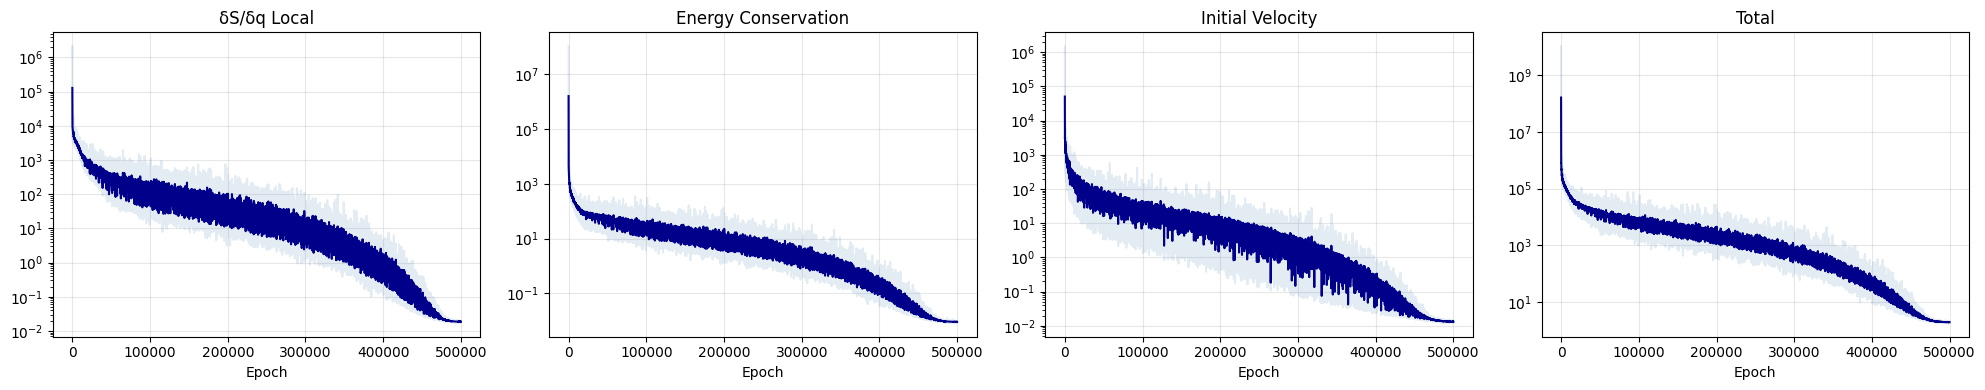

In [54]:
# %% Gráfica de pérdidas
def smooth(v, w=100):
    return np.convolve(v, np.ones(w)/w, mode='valid')

fig, axes = plt.subplots(1, 4, figsize=(20, 4))
for ax, key, title in zip(axes,
    ["station", "energy", "vel_ic", "total"],
    ["δS/δq Local", "Energy Conservation", "Initial Velocity", "Total"]):
    raw = np.array(history[key])
    ax.semilogy(raw, alpha=0.15, color='steelblue')
    if len(raw) > 200:
        ax.semilogy(smooth(raw, 200), color='darkblue', lw=1.5)
    ax.set_title(title); ax.set_xlabel("Epoch"); ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


# Results


In [94]:

def generate_testing_map(scale = 2, dm = 0.1):

    x_min, x_max = -15, 15
    y_min, y_max = -15, 15
    vx_min, vx_max = -15, 15
    vy_min, vy_max = -15, 15

    if scale != 1:
        x_range = x_max - x_min
        y_range = y_max - y_min 
        vx_range = vx_max - vx_min
        vy_range = vy_max - vy_min

        x_min = x_min - scale * x_range 
        x_max = x_max + scale * x_range 

        y_min = y_min - scale * y_range 
        y_max = y_max + scale * y_range 

        vx_min = vx_min - scale * vx_range
        vx_max = vx_max + scale * vx_range

        vy_min = vy_min - scale * vy_range
        vy_max = vy_max + scale * vy_range

    x0_mesh = np.arange(x_min, x_max, dm)
    y0_mesh = np.arange(y_min, y_max, dm)
    vx0_mesh = np.arange(vx_min, vx_max, dm)
    vy0_mesh = np.arange(vy_min, vy_max)

    return x0_mesh, y0_mesh, vx0_mesh, vy0_mesh

In [ ]:
def plot_trajectory_comparison(model, ic, title_suffix="", display=True):
    x0, y0, vx0, vy0 = ic
    ic_t = torch.tensor(ic, dtype=torch.float32).unsqueeze(0).to(device)
    with torch.no_grad():
        pred = model(ic_t).cpu().numpy()[0]
    x_nn = np.concatenate([[x0], pred[:N]])
    y_nn = np.concatenate([[y0], pred[N:]])
    x_an, y_an = analytical_trajectory(x0, y0, vx0, vy0)
    x_an = np.concatenate([[x0], x_an])
    y_an = np.concatenate([[y0], y_an])
    t_arr = np.arange(0, N + 1) * dt

    vx_nn = np.diff(x_nn) / dt
    vy_nn = np.diff(y_nn) / dt
    y_mid = (y_nn[1:] + y_nn[:-1]) / 2
    E_nn = 0.5*m*(vx_nn**2+vy_nn**2) + m*9.81*y_mid
    E0_val = 0.5*m*(vx0**2+vy0**2) + m*9.81*y0

    if display:
        fig, axes = plt.subplots(2, 2, figsize=(14, 10))

        ax = axes[0, 0]
        ax.plot(x_an, y_an, 'k--', lw=2.5, label='Analytic')
        ax.plot(x_nn, y_nn, 'ro-', ms=5, lw=1.5, label='Neural Network', alpha=0.8)
        ax.scatter([x0], [y0], c='green', s=100, zorder=10, label='Start')
        ax.set_xlabel("x (m)"); ax.set_ylabel("y (m)")
        ax.set_title("Trajectory x-y"); ax.legend()
        ax.grid(True, alpha=0.3); ax.set_aspect('equal')

        ax = axes[0, 1]
        ax.plot(t_arr, x_an, 'b--', lw=2, label='x analytic')
        ax.plot(t_arr, x_nn, 'b^-', ms=4, lw=1, alpha=0.7, label='x NN')
        ax.plot(t_arr, y_an, 'r--', lw=2, label='y analytic')
        ax.plot(t_arr, y_nn, 'rs-', ms=4, lw=1, alpha=0.7, label='y NN')
        ax.set_xlabel("t (s)"); ax.set_ylabel("position (m)")
        ax.set_title("Position vs Time"); ax.legend(ncol=2); ax.grid(True, alpha=0.3)

        ax = axes[1, 0]
        ax.plot(t_arr, np.abs(x_nn - x_an), 'b.-', label='|Δx|')
        ax.plot(t_arr, np.abs(y_nn - y_an), 'r.-', label='|Δy|')
        ax.set_xlabel("t (s)"); ax.set_ylabel("Absolute Error (m)")
        ax.set_title("Absolute Error"); ax.legend(); ax.grid(True, alpha=0.3)

        ax = axes[1, 1]

        ax.plot(E_nn, 'bo-', ms=4, label='E(t) predicted')
        ax.axhline(E0_val, color='r', ls='--', lw=2, label=f'E₀={E0_val:.2f} J')
        ax.set_xlabel("Time step"); ax.set_ylabel("E (J)")
        ax.set_title("Energy Conservation"); ax.legend(); ax.grid(True, alpha=0.3)

        fig.suptitle(f"IC: x₀={x0:.1f}, y₀={y0:.1f}, vx₀={vx0:.1f}, vy₀={vy0:.1f}  "
                    f"{title_suffix}", fontsize=13, fontweight='bold')
        plt.tight_layout(); plt.show()

        rmse_x = np.sqrt(np.mean((x_nn - x_an)**2))
        rmse_y = np.sqrt(np.mean((y_nn - y_an)**2))
        print(f"  RMSE_x={rmse_x:.4f} m | RMSE_y={rmse_y:.4f} m | σ(E)={np.std(E_nn):.4f} J")

    return x_nn - x_an, y_nn - y_an, E_nn - E0_val, x_an, y_an, E0_val

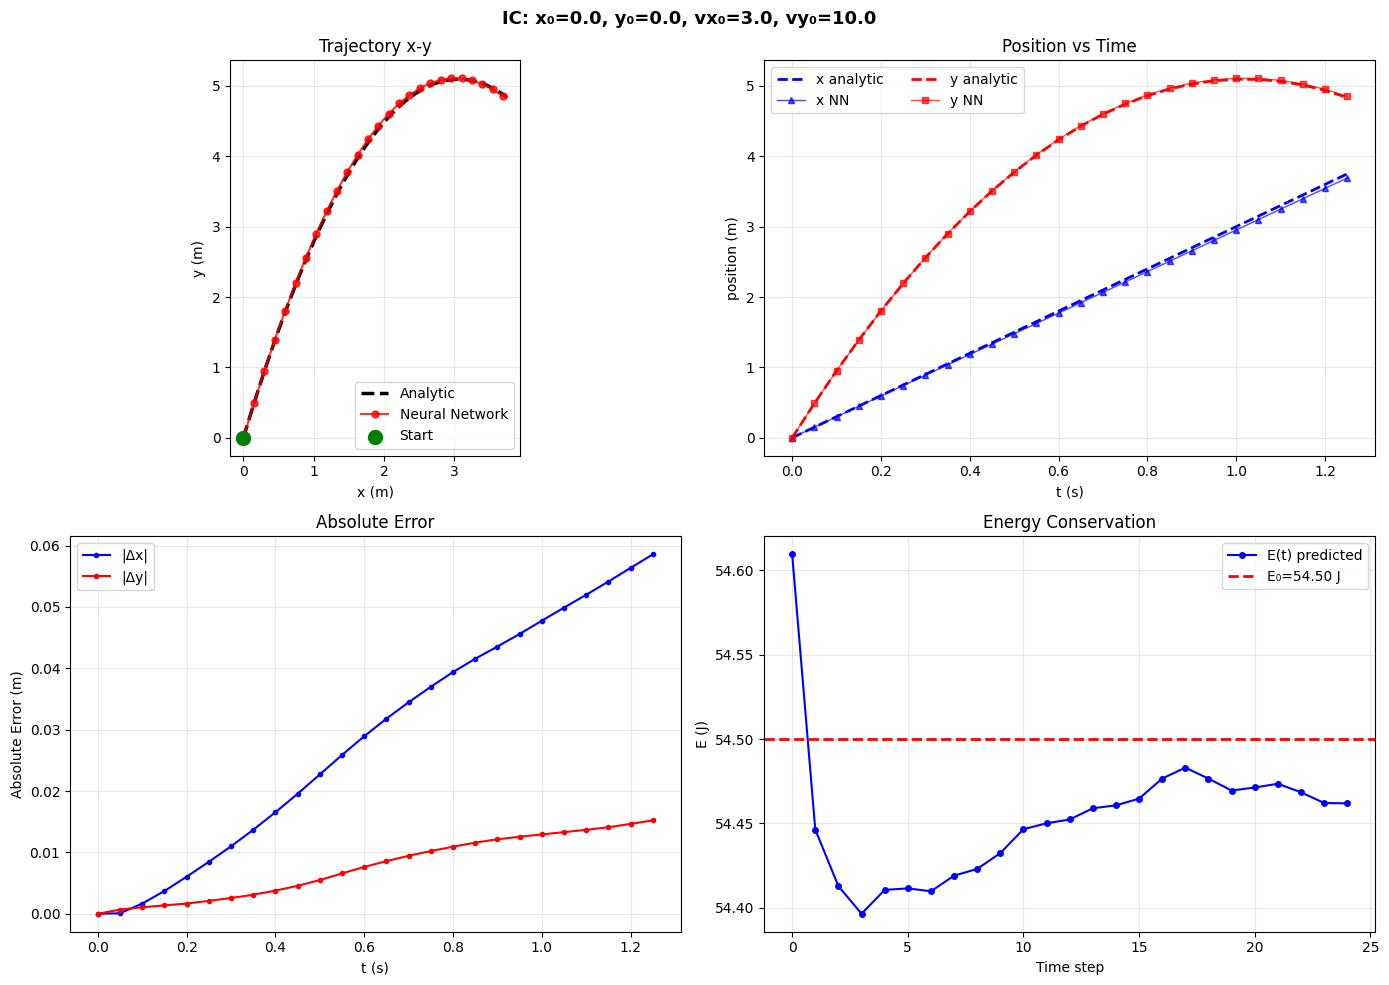

  RMSE_x=0.0345 m | RMSE_y=0.0092 m | σ(E)=0.0405 J


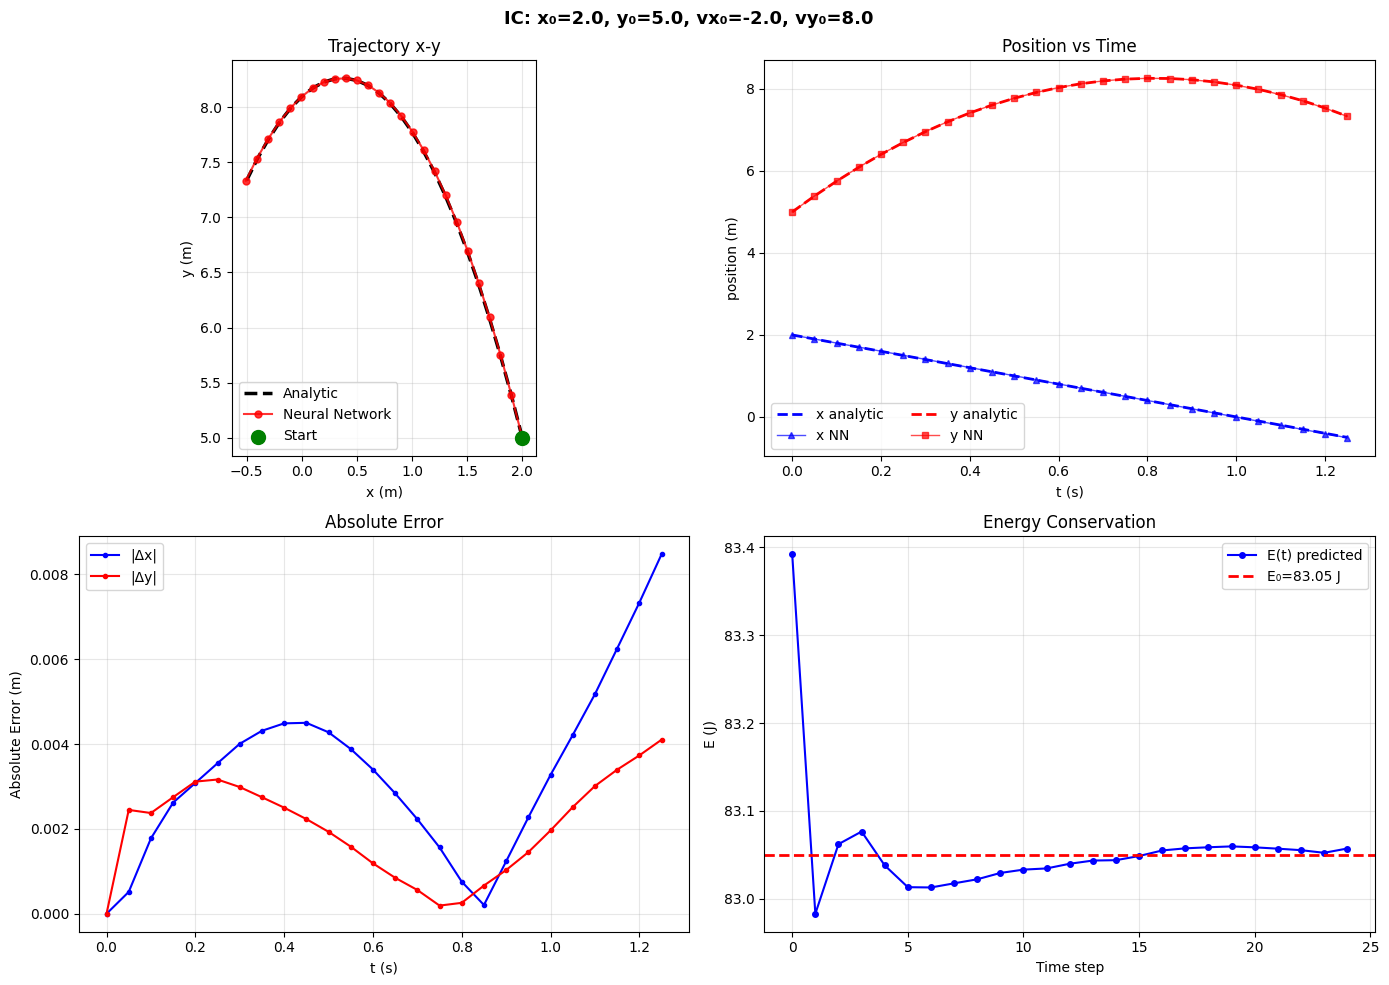

  RMSE_x=0.0039 m | RMSE_y=0.0023 m | σ(E)=0.0715 J


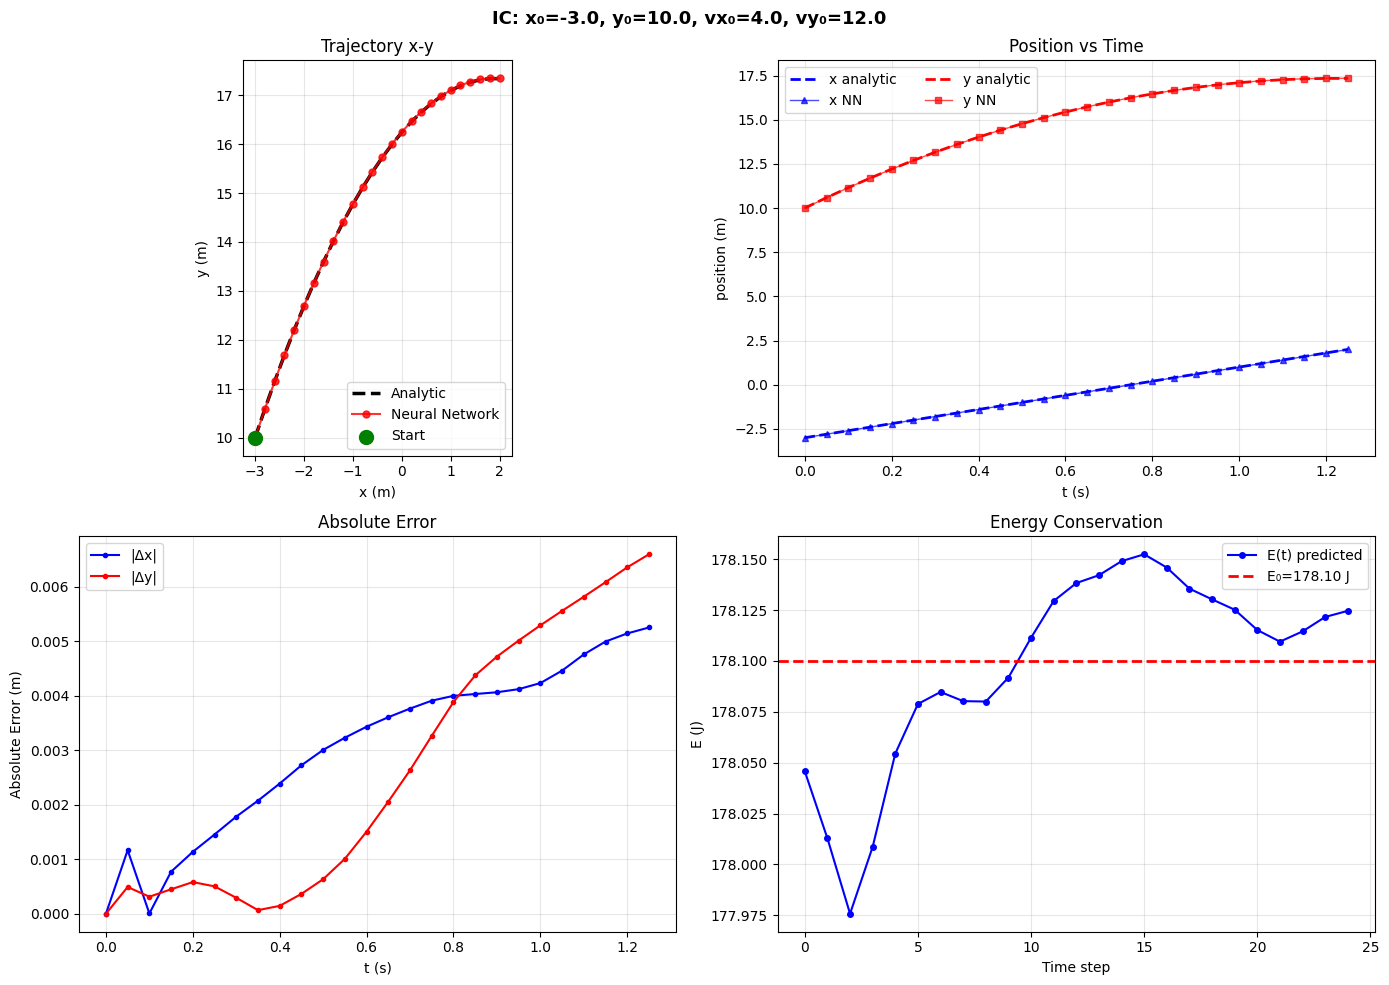

  RMSE_x=0.0034 m | RMSE_y=0.0035 m | σ(E)=0.0464 J


In [ ]:
test_conditions = np.array([
    [0.0, 0.0, 3.0, 10.0],
    [2.0, 5.0, -2.0, 8.0],
    [-3.0, 10.0, 4.0, 12.0],
], dtype=np.float32)

for i, ic in enumerate(test_conditions):
    plot_trajectory_comparison(model, ic, title_suffix=f"")


In [99]:
# %% Ejecutar comparaciones
test_conditions = generate_batch(10000)

x_errors_vector = []
y_errors_vector = []
energy_errors_vector = []

all_x_true = []
all_y_true = []
all_energy_true = []

for i, ic in enumerate(test_conditions):
    x_errors, y_errors, energy_errors, x_true, y_true, energy_true = plot_trajectory_comparison(model, ic, title_suffix=f"(Test {i+1})", display=False)
    x_errors_vector.append(x_errors)
    y_errors_vector.append(y_errors)
    energy_errors_vector.append(energy_errors)

    all_x_true.append(x_true)    
    all_y_true.append(y_true)    
    all_energy_true.append(energy_true)

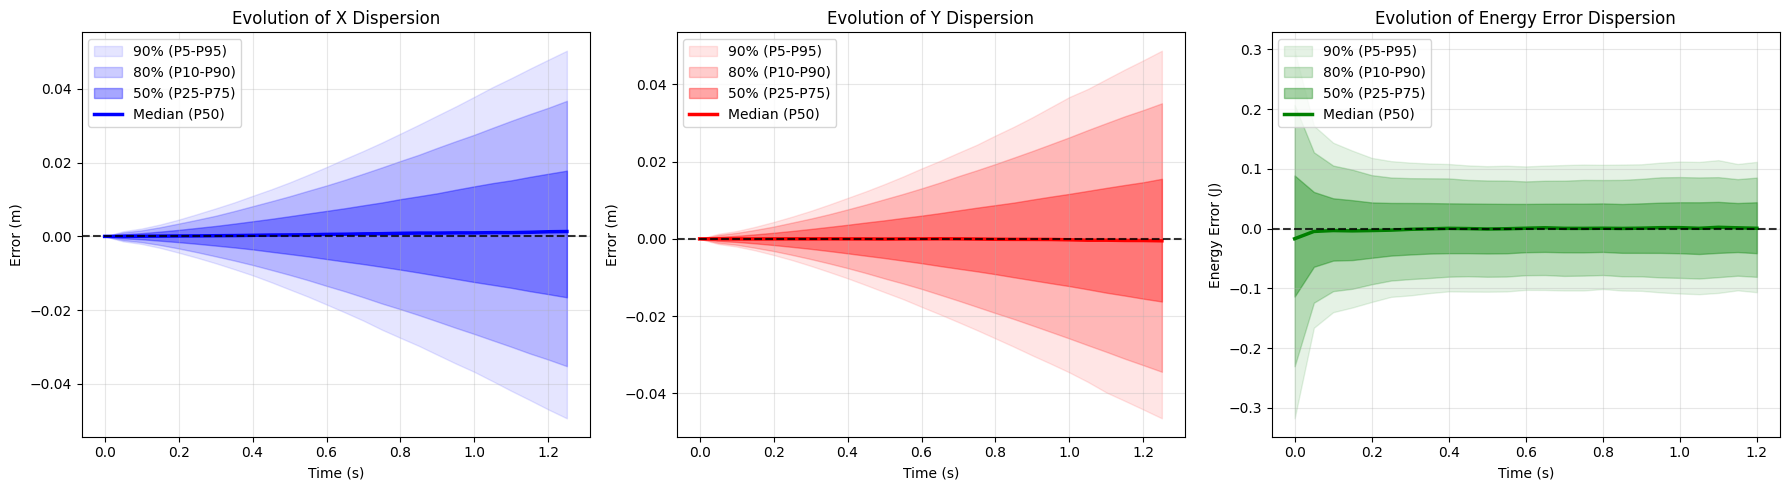

In [ ]:
time_vector = np.arange(0, N + 1) * dt

all_x_errors = np.array(x_errors_vector)
all_y_errors = np.array(y_errors_vector)
all_energy_errors = np.array(energy_errors_vector)

x_mean_err = np.mean(all_x_errors, axis=0)
y_mean_err = np.mean(all_y_errors, axis=0)
energy_mean_err = np.mean(all_energy_errors, axis=0)

x_std = np.std(all_x_errors, axis=0)
y_std = np.std(all_y_errors, axis=0)
energy_std = np.std(all_energy_errors, axis=0)

x_p10, x_median, x_p90 = np.percentile(all_x_errors, [10, 50, 90], axis=0)
y_p10, y_median, y_p90 = np.percentile(all_y_errors, [10, 50, 90], axis=0)
e_p10, e_median, e_p90 = np.percentile(all_energy_errors, [10, 50, 90], axis=0)


percentiles_objetivo = [5, 10, 25, 50, 75, 90, 95]

x_p5, x_p10, x_p25, x_median, x_p75, x_p90, x_p95 = np.percentile(all_x_errors, percentiles_objetivo, axis=0)
y_p5, y_p10, y_p25, y_median, y_p75, y_p90, y_p95 = np.percentile(all_y_errors, percentiles_objetivo, axis=0)
e_p5, e_p10, e_p25, e_median, e_p75, e_p90, e_p95 = np.percentile(all_energy_errors, percentiles_objetivo, axis=0)

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

alpha_outer = 0.1   
alpha_mid = 0.2     
alpha_inner = 0.35  

axes[0].fill_between(time_vector, x_p5, x_p95, color='blue', alpha=alpha_outer, label='90% (P5-P95)')
axes[0].fill_between(time_vector, x_p10, x_p90, color='blue', alpha=alpha_mid, label='80% (P10-P90)')
axes[0].fill_between(time_vector, x_p25, x_p75, color='blue', alpha=alpha_inner, label='50% (P25-P75)')
axes[0].plot(time_vector, x_median, color='blue', lw=2.5, label='Median (P50)')

axes[0].axhline(0, color='black', linestyle='--', alpha=0.8, lw=1.5)
axes[0].set_title("Evolution of X Dispersion")
axes[0].set_xlabel("Time (s)")
axes[0].set_ylabel("Error (m)")
axes[0].grid(True, alpha=0.3)
axes[0].legend(loc='upper left')

# 2. Eje Y
axes[1].fill_between(time_vector, y_p5, y_p95, color='red', alpha=alpha_outer, label='90% (P5-P95)')
axes[1].fill_between(time_vector, y_p10, y_p90, color='red', alpha=alpha_mid, label='80% (P10-P90)')
axes[1].fill_between(time_vector, y_p25, y_p75, color='red', alpha=alpha_inner, label='50% (P25-P75)')
axes[1].plot(time_vector, y_median, color='red', lw=2.5, label='Median (P50)')

axes[1].axhline(0, color='black', linestyle='--', alpha=0.8, lw=1.5)
axes[1].set_title("Evolution of Y Dispersion")
axes[1].set_xlabel("Time (s)")
axes[1].set_ylabel("Error (m)")
axes[1].grid(True, alpha=0.3)
axes[1].legend(loc='upper left')

# 3. Energía
time_vector = np.arange(0, N ) * dt
axes[2].fill_between(time_vector, e_p5, e_p95, color='green', alpha=alpha_outer, label='90% (P5-P95)')
axes[2].fill_between(time_vector, e_p10, e_p90, color='green', alpha=alpha_mid, label='80% (P10-P90)')
axes[2].fill_between(time_vector, e_p25, e_p75, color='green', alpha=alpha_inner, label='50% (P25-P75)')
axes[2].plot(time_vector, e_median, color='green', lw=2.5, label='Median (P50)')

axes[2].axhline(0, color='black', linestyle='--', alpha=0.8, lw=1.5)
axes[2].set_title("Evolution of Energy Error Dispersion")
axes[2].set_xlabel("Time (s)")
axes[2].set_ylabel("Energy Error (J)")
axes[2].grid(True, alpha=0.3)
axes[2].legend(loc='upper left')

plt.tight_layout()
plt.show()

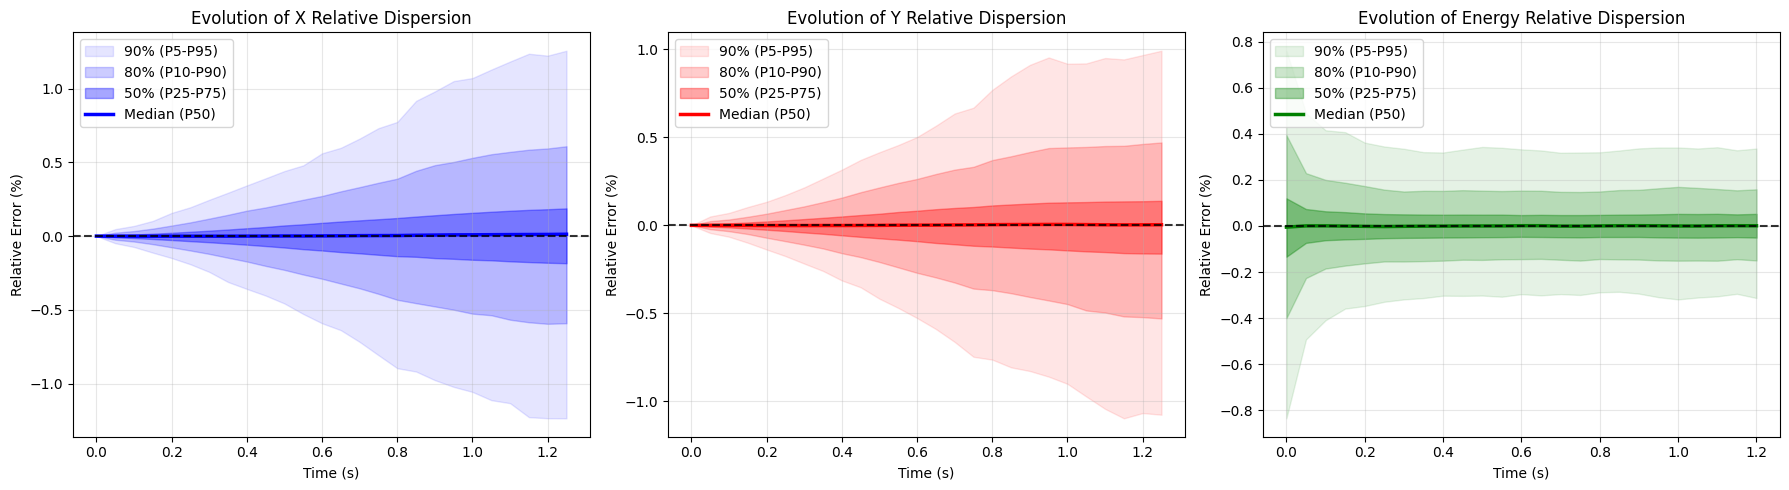

In [106]:
time_vector_pos = np.arange(0, N + 1) * dt
time_vector_eng = np.arange(0, N) * dt

all_x_errors = np.array(x_errors_vector) 
all_y_errors = np.array(y_errors_vector)
all_energy_errors = np.array(energy_errors_vector)

all_x_true = np.array(all_x_true)
all_y_true = np.array(all_y_true)
all_energy_true = np.array(all_energy_true)

all_energy_true_expanded = all_energy_true[:, None]

all_x_pct = np.where(all_x_true != 0, (all_x_errors / all_x_true) * 100, 0)
all_y_pct = np.where(all_y_true != 0, (all_y_errors / all_y_true) * 100, 0)
all_energy_pct = np.where(all_energy_true_expanded != 0, (all_energy_errors / all_energy_true_expanded) * 100, 0)


x_mean_err = np.mean(all_x_pct, axis=0)
y_mean_err = np.mean(all_y_pct, axis=0)
energy_mean_err = np.mean(all_energy_pct, axis=0)

x_std = np.std(all_x_pct, axis=0)
y_std = np.std(all_y_pct, axis=0)
energy_std = np.std(all_energy_pct, axis=0)

percentiles_objetivo = [5, 10, 25, 50, 75, 90, 95]

x_p5, x_p10, x_p25, x_median, x_p75, x_p90, x_p95 = np.percentile(all_x_pct, percentiles_objetivo, axis=0)
y_p5, y_p10, y_p25, y_median, y_p75, y_p90, y_p95 = np.percentile(all_y_pct, percentiles_objetivo, axis=0)
e_p5, e_p10, e_p25, e_median, e_p75, e_p90, e_p95 = np.percentile(all_energy_pct, percentiles_objetivo, axis=0)

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

alpha_outer = 0.1   
alpha_mid = 0.2     
alpha_inner = 0.35  

axes[0].fill_between(time_vector_pos, x_p5, x_p95, color='blue', alpha=alpha_outer, label='90% (P5-P95)')
axes[0].fill_between(time_vector_pos, x_p10, x_p90, color='blue', alpha=alpha_mid, label='80% (P10-P90)')
axes[0].fill_between(time_vector_pos, x_p25, x_p75, color='blue', alpha=alpha_inner, label='50% (P25-P75)')
axes[0].plot(time_vector_pos, x_median, color='blue', lw=2.5, label='Median (P50)')
axes[0].axhline(0, color='black', linestyle='--', alpha=0.8, lw=1.5)
axes[0].set_title("Evolution of X Relative Dispersion")
axes[0].set_xlabel("Time (s)")
axes[0].set_ylabel("Relative Error (%)")
axes[0].grid(True, alpha=0.3)
axes[0].legend(loc='upper left')

axes[1].fill_between(time_vector_pos, y_p5, y_p95, color='red', alpha=alpha_outer, label='90% (P5-P95)')
axes[1].fill_between(time_vector_pos, y_p10, y_p90, color='red', alpha=alpha_mid, label='80% (P10-P90)')
axes[1].fill_between(time_vector_pos, y_p25, y_p75, color='red', alpha=alpha_inner, label='50% (P25-P75)')
axes[1].plot(time_vector_pos, y_median, color='red', lw=2.5, label='Median (P50)')
axes[1].axhline(0, color='black', linestyle='--', alpha=0.8, lw=1.5)
axes[1].set_title("Evolution of Y Relative Dispersion")
axes[1].set_xlabel("Time (s)")
axes[1].set_ylabel("Relative Error (%)")
axes[1].grid(True, alpha=0.3)
axes[1].legend(loc='upper left')

axes[2].fill_between(time_vector_eng, e_p5, e_p95, color='green', alpha=alpha_outer, label='90% (P5-P95)')
axes[2].fill_between(time_vector_eng, e_p10, e_p90, color='green', alpha=alpha_mid, label='80% (P10-P90)')
axes[2].fill_between(time_vector_eng, e_p25, e_p75, color='green', alpha=alpha_inner, label='50% (P25-P75)')
axes[2].plot(time_vector_eng, e_median, color='green', lw=2.5, label='Median (P50)')
axes[2].axhline(0, color='black', linestyle='--', alpha=0.8, lw=1.5)
axes[2].set_title("Evolution of Energy Relative Dispersion")
axes[2].set_xlabel("Time (s)")
axes[2].set_ylabel("Relative Error (%)")
axes[2].grid(True, alpha=0.3)
axes[2].legend(loc='upper left')

plt.tight_layout()
plt.show()

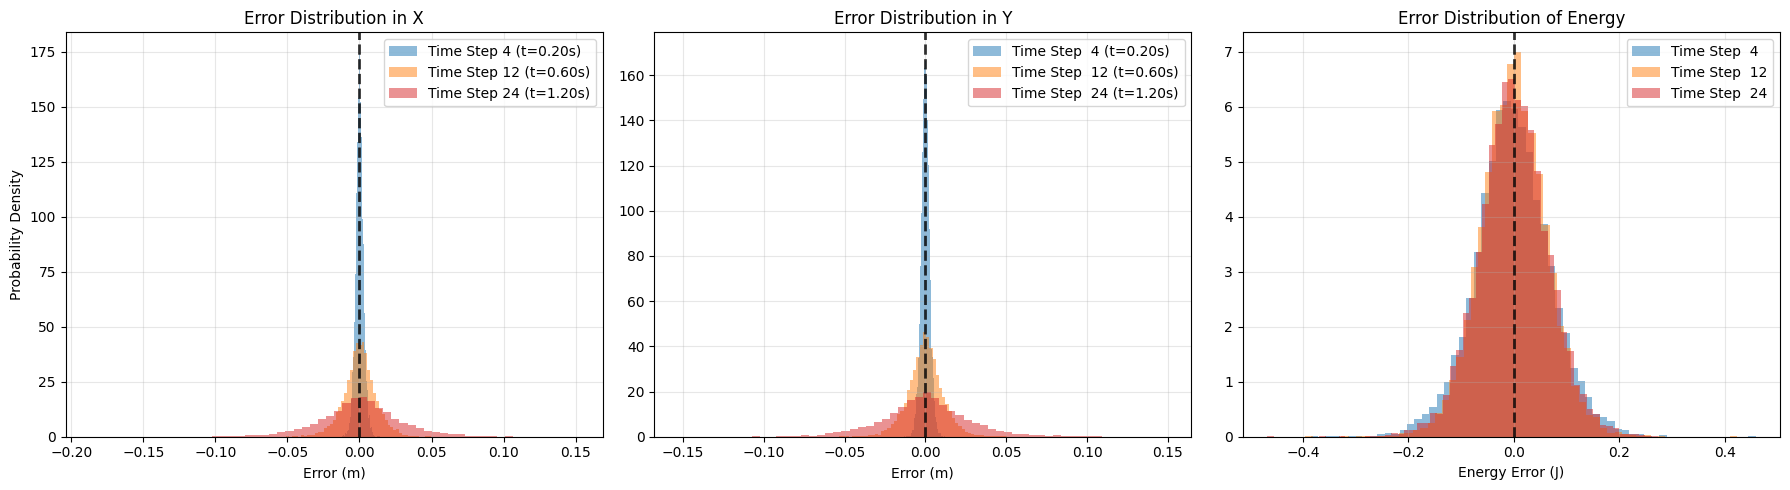

In [ ]:

pasos_objetivo = [4, 12, 24] 
colores = ['#1f77b4', '#ff7f0e', '#d62728'] 

fig, axes = plt.subplots(1, 3, figsize=(18, 5))


for i, paso in enumerate(pasos_objetivo):
    datos_corte = all_x_errors[:, paso]
    
    axes[0].hist(
        datos_corte, 
        bins=60, 
        alpha=0.5, 
        color=colores[i], 
        density=True, 
        label=f'Time Step {paso} (t={paso*dt:.2f}s)'
    )
    
axes[0].axvline(0, color='black', linestyle='--', linewidth=2, alpha=0.8)
axes[0].set_title("Error Distribution in X")
axes[0].set_xlabel("Error (m)")
axes[0].set_ylabel("Probability Density")
axes[0].grid(True, alpha=0.3)
axes[0].legend()

for i, paso in enumerate(pasos_objetivo):
    datos_corte = all_y_errors[:, paso]
    
    axes[1].hist(
        datos_corte, 
        bins=60, 
        alpha=0.5, 
        color=colores[i], 
        density=True, 
        label=f'Time Step  {paso} (t={paso*dt:.2f}s)'
    )
    
axes[1].axvline(0, color='black', linestyle='--', linewidth=2, alpha=0.8)
axes[1].set_title("Error Distribution in Y")
axes[1].set_xlabel("Error (m)")
axes[1].grid(True, alpha=0.3)
axes[1].legend()


for i, paso in enumerate(pasos_objetivo):
    if paso >= all_energy_errors.shape[1]:
        paso_E = all_energy_errors.shape[1] - 1
    else:
        paso_E = paso
        
    datos_corte = all_energy_errors[:, paso_E]
    
    axes[2].hist(
        datos_corte, 
        bins=60, 
        alpha=0.5, 
        color=colores[i], 
        density=True, 
        label=f'Time Step  {paso_E}'
    )

axes[2].axvline(0, color='black', linestyle='--', linewidth=2, alpha=0.8)
axes[2].set_title("Error Distribution of Energy")
axes[2].set_xlabel("Energy Error (J)")
axes[2].grid(True, alpha=0.3)
axes[2].legend()

plt.tight_layout()
plt.show()

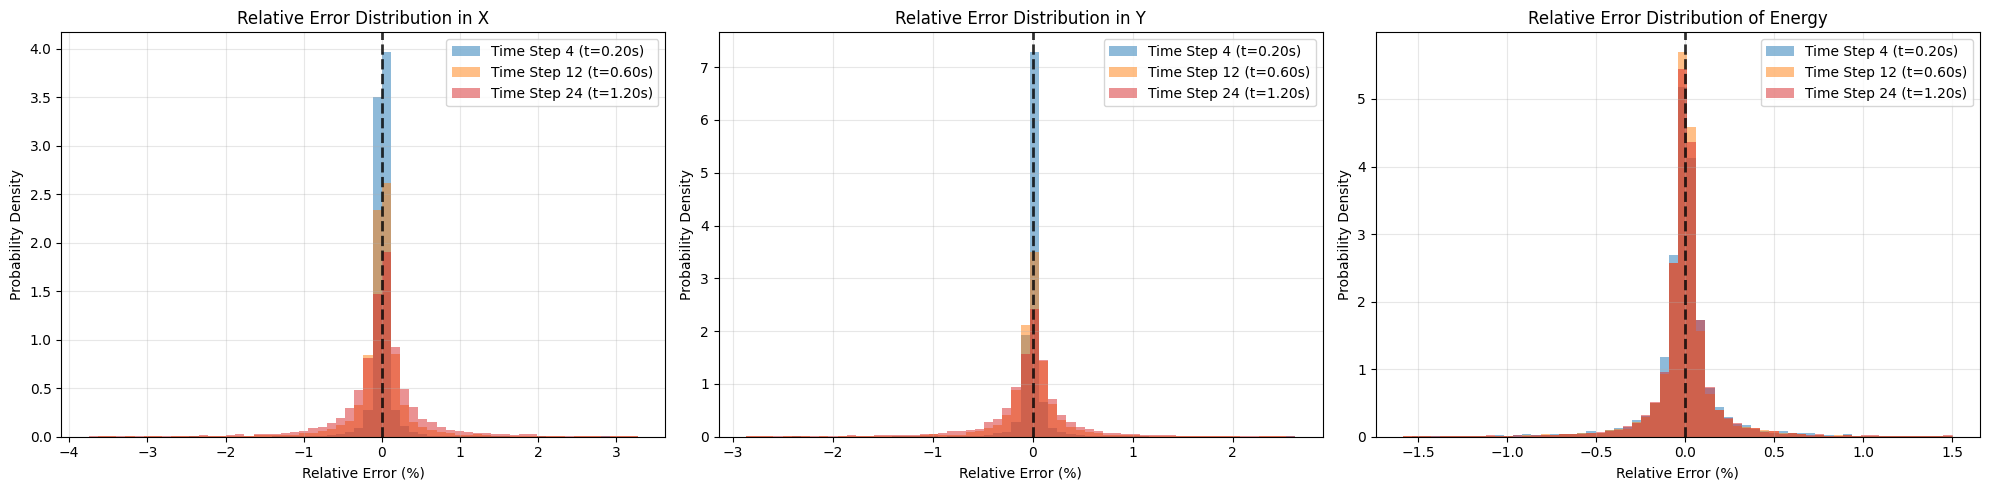

In [110]:

pasos_objetivo = [4, 12, 24] 
colores = ['#1f77b4', '#ff7f0e', '#d62728'] 

fig, axes = plt.subplots(1, 3, figsize=(20, 5))

x_min = np.percentile(all_x_pct[:, pasos_objetivo], 1)
x_max = np.percentile(all_x_pct[:, pasos_objetivo], 99)

for i, paso in enumerate(pasos_objetivo):
    datos_corte = all_x_pct[:, paso]
    axes[0].hist(
        datos_corte, 
        bins=60, 
        range=(x_min, x_max),  
        alpha=0.5, 
        color=colores[i], 
        density=True, 
        label=f'Time Step {paso} (t={paso*dt:.2f}s)'
    )
    
axes[0].axvline(0, color='black', linestyle='--', linewidth=2, alpha=0.8)
axes[0].set_title("Relative Error Distribution in X")
axes[0].set_xlabel("Relative Error (%)")
axes[0].set_ylabel("Probability Density")
axes[0].grid(True, alpha=0.3)
axes[0].legend()

y_min = np.percentile(all_y_pct[:, pasos_objetivo], 1)
y_max = np.percentile(all_y_pct[:, pasos_objetivo], 99)

for i, paso in enumerate(pasos_objetivo):
    datos_corte = all_y_pct[:, paso]
    axes[1].hist(
        datos_corte, 
        bins=60, 
        range=(y_min, y_max), 
        alpha=0.5, 
        color=colores[i], 
        density=True, 
        label=f'Time Step {paso} (t={paso*dt:.2f}s)'
    )
    
axes[1].axvline(0, color='black', linestyle='--', linewidth=2, alpha=0.8)
axes[1].set_title("Relative Error Distribution in Y")
axes[1].set_xlabel("Relative Error (%)")
axes[1].set_ylabel("Probability Density")
axes[1].grid(True, alpha=0.3)
axes[1].legend()

pasos_E = [p if p < all_energy_pct.shape[1] else all_energy_pct.shape[1] - 1 for p in pasos_objetivo]
e_min = np.percentile(all_energy_pct[:, pasos_E], 1)
e_max = np.percentile(all_energy_pct[:, pasos_E], 99)

for i, paso in enumerate(pasos_objetivo):
    paso_E = paso if paso < all_energy_pct.shape[1] else all_energy_pct.shape[1] - 1
    datos_corte = all_energy_pct[:, paso_E]
    axes[2].hist(
        datos_corte, 
        bins=60, 
        range=(e_min, e_max),  
        alpha=0.5, 
        color=colores[i], 
        density=True, 
        label=f'Time Step {paso_E} (t={paso_E*dt:.2f}s)'
    )

axes[2].axvline(0, color='black', linestyle='--', linewidth=2, alpha=0.8)
axes[2].set_title("Relative Error Distribution of Energy")
axes[2].set_xlabel("Relative Error (%)")
axes[2].set_ylabel("Probability Density")
axes[2].grid(True, alpha=0.3)
axes[2].legend()

plt.tight_layout()
plt.show()

## Out of Range MSE


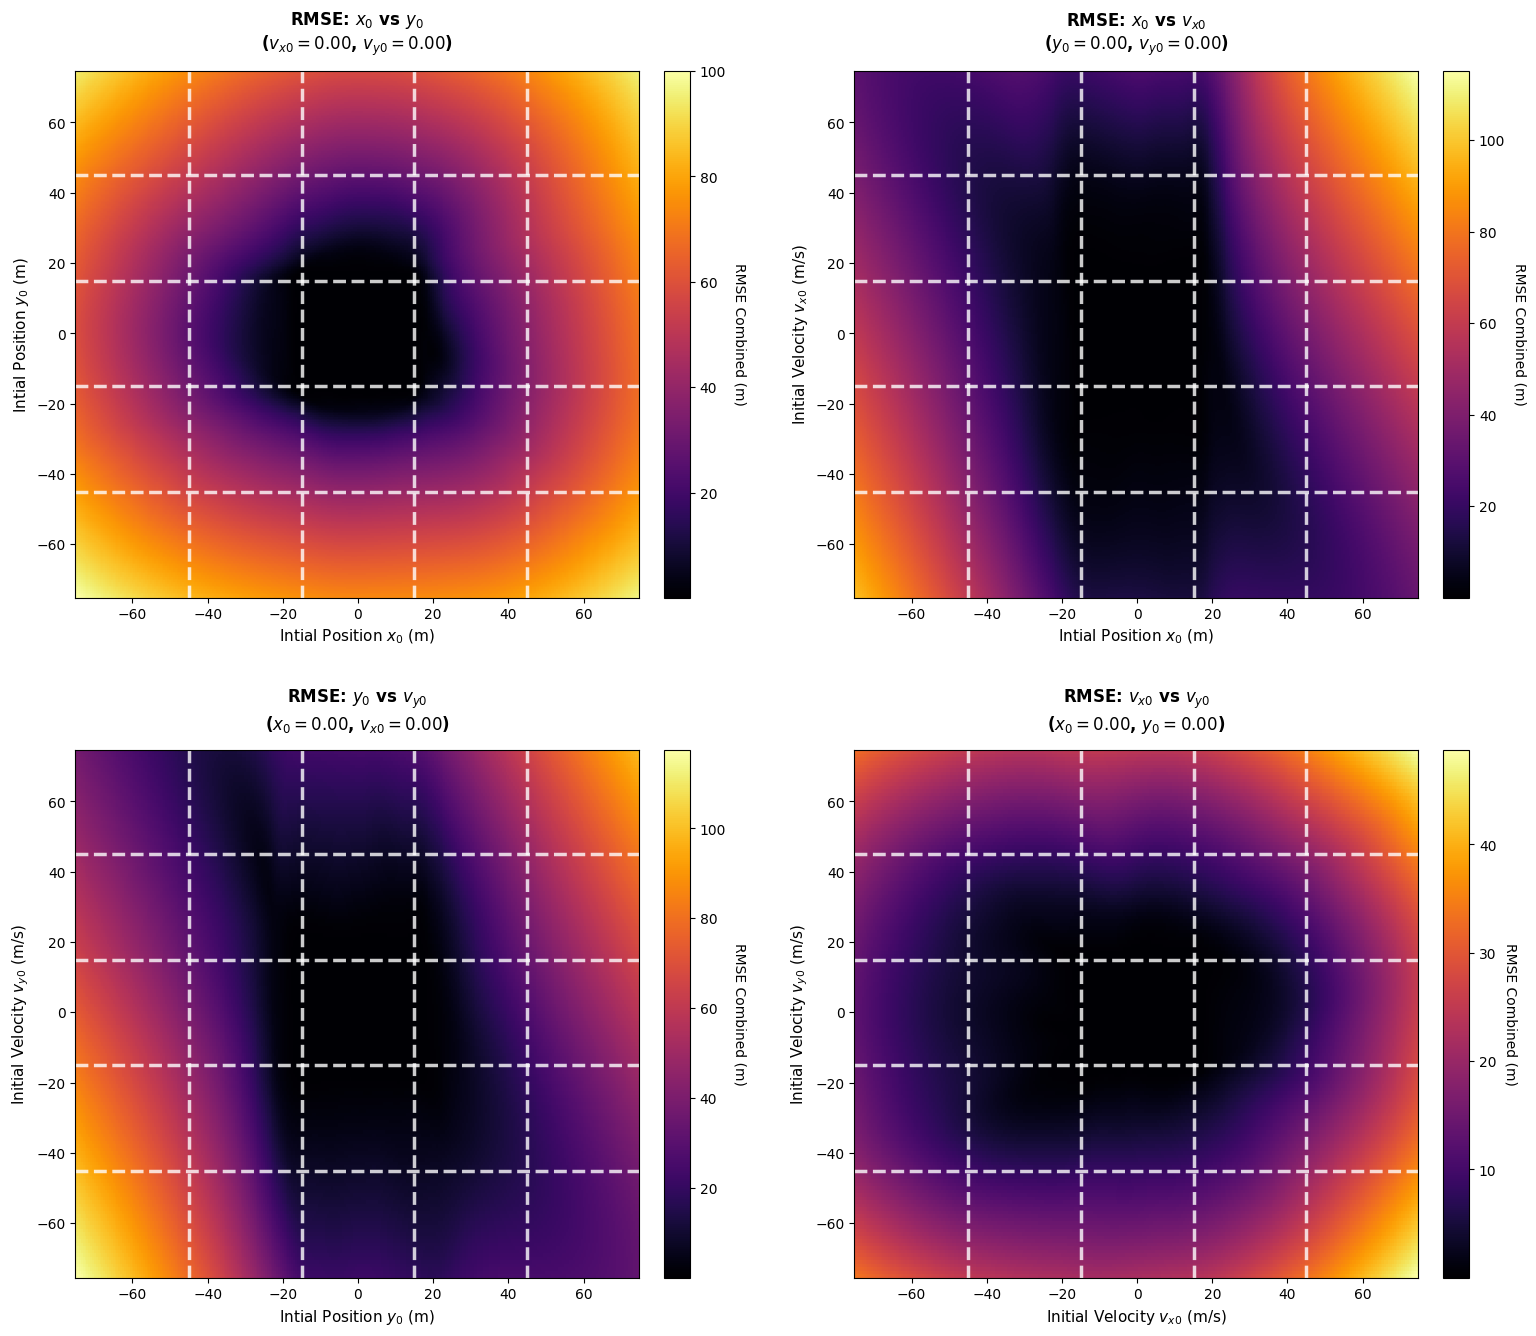

In [ ]:


x0_vals, y0_vals, vx0_vals, vy0_vals = generate_testing_map(scale=2, dm = 0.5)


c_x0 = x0_vals[len(x0_vals) // 2]
c_y0 = y0_vals[len(y0_vals) // 2]
c_vx0 = vx0_vals[len(vx0_vals) // 2]
c_vy0 = vy0_vals[len(vy0_vals) // 2]

def compute_rmse_slice(model, var_x_vals, var_y_vals, fixed_dict, var_names):
    """
    Evalúa el RMSE posicional del modelo sobre un corte 2D del espacio de fase.
    """
    X, Y = np.meshgrid(var_x_vals, var_y_vals)
    flat_X = X.ravel()
    flat_Y = Y.ravel()
    batch_size = len(flat_X)
    
    data = np.zeros((batch_size, 4), dtype=np.float32)
    
    mapping = {'x0': 0, 'y0': 1, 'vx0': 2, 'vy0': 3}
    data[:, mapping[var_names[0]]] = flat_X
    data[:, mapping[var_names[1]]] = flat_Y
    
    for fixed_name, fixed_val in fixed_dict.items():
        data[:, mapping[fixed_name]] = fixed_val
        
    batch_tensor = torch.from_numpy(data).to(device)
    
    with torch.no_grad():
        pred = model(batch_tensor).cpu().numpy() # (B, 2*N)
        
    x_nn = pred[:, :N]
    y_nn = pred[:, N:]
    
    t_arr = np.arange(1, N + 1) * dt
    x0_arr = data[:, 0:1]
    y0_arr = data[:, 1:2]
    vx0_arr = data[:, 2:3]
    vy0_arr = data[:, 3:4]
    
    x_an = x0_arr + vx0_arr * t_arr
    y_an = y0_arr + vy0_arr * t_arr + 0.5 * g * t_arr**2
    
    mse_x = np.mean((x_nn - x_an)**2, axis=1)
    mse_y = np.mean((y_nn - y_an)**2, axis=1)
    rmse_total = np.sqrt(mse_x + mse_y)
    
    return X, Y, rmse_total.reshape(X.shape)

slices = [
    {
        'vars': (x0_vals, y0_vals), 'names': ('x0', 'y0'),
        'fixed': {'vx0': c_vx0, 'vy0': c_vy0},
        'labels': ('Intial Position $x_0$ (m)', 'Intial Position $y_0$ (m)'),
        'title': f'RMSE: $x_0$ vs $y_0$\n($v_{{x0}}={c_vx0:.2f}$, $v_{{y0}}={c_vy0:.2f}$)'
    },
    {
        'vars': (x0_vals, vx0_vals), 'names': ('x0', 'vx0'),
        'fixed': {'y0': c_y0, 'vy0': c_vy0},
        'labels': ('Intial Position $x_0$ (m)', 'Initial Velocity $v_{x0}$ (m/s)'),
        'title': f'RMSE: $x_0$ vs $v_{{x0}}$\n($y_0={c_y0:.2f}$, $v_{{y0}}={c_vy0:.2f}$)'
    },
    {
        'vars': (y0_vals, vy0_vals), 'names': ('y0', 'vy0'),
        'fixed': {'x0': c_x0, 'vx0': c_vx0},
        'labels': ('Intial Position $y_0$ (m)', 'Initial Velocity $v_{y0}$ (m/s)'),
        'title': f'RMSE: $y_0$ vs $v_{{y0}}$\n($x_0={c_x0:.2f}$, $v_{{x0}}={c_vx0:.2f}$)'
    },
    {
        'vars': (vx0_vals, vy0_vals), 'names': ('vx0', 'vy0'),
        'fixed': {'x0': c_x0, 'y0': c_y0},
        'labels': ('Initial Velocity $v_{x0}$ (m/s)', 'Initial Velocity $v_{y0}$ (m/s)'),
        'title': f'RMSE: $v_{{x0}}$ vs $v_{{y0}}$\n($x_0={c_x0:.2f}$, $y_0={c_y0:.2f}$)'
    }
]

def obtener_cuatro_referencias(nombre_variable, arreglo_dominio):
    """
    Inyecta 4 valores de referencia ortogonales condicionados a la dimensión del espacio de fase.
    Permite mezclar valores escalares absolutos con extracciones indexadas del dominio de entrada.
    """
 
    x_min, x_max = -15, 15
    y_min, y_max = -15, 15
    vx_min, vx_max = -15, 15
    vy_min, vy_max = -15, 15

    x_range = x_max - x_min
    y_range = y_max - y_min
    vx_range = vx_max - vx_min 
    vy_range = vy_max - vy_min 

    if nombre_variable == 'x0':
        return [x_min - x_range, x_min, x_max, x_max + x_range]
        
    elif nombre_variable == 'y0':
        return [y_min - y_range, y_min, y_max, y_max + y_range]

    elif nombre_variable == 'vx0':
        return [vx_min - vx_range, vx_min, vx_max, vx_max + vx_range]
        
    elif nombre_variable == 'vy0':
        return [vy_min - vy_range, vy_min, vy_max, vy_max + vy_range]
        
    else:
        indices = np.linspace(0, len(arreglo_dominio) - 1, 6, dtype=int)[1:-1]
        return arreglo_dominio[indices]

valores_referencia = {
    'x0': obtener_cuatro_referencias('x0', x0_vals),
    'y0': obtener_cuatro_referencias('y0', y0_vals),
    'vx0': obtener_cuatro_referencias('vx0', vx0_vals),
    'vy0': obtener_cuatro_referencias('vy0', vy0_vals)
}

fig, axes = plt.subplots(2, 2, figsize=(16, 14))
axes = axes.ravel()

for i, config in enumerate(slices):
    X, Y, Z_rmse = compute_rmse_slice(
        model, config['vars'][0], config['vars'][1], config['fixed'], config['names']
    )
    
    ax = axes[i]
    im = ax.pcolormesh(X, Y, Z_rmse, cmap='inferno', shading='auto')
    
    var_x_name = config['names'][0]
    var_y_name = config['names'][1]
    
    refs_x = valores_referencia[var_x_name]
    refs_y = valores_referencia[var_y_name]
    
    for val_x in refs_x:
        ax.axvline(
            x=val_x, 
            color='white', 
            linestyle='--', 
            linewidth=2.5,  
            alpha=0.8
        )
        
    for val_y in refs_y:
        ax.axhline(
            y=val_y, 
            color='white', 
            linestyle='--', 
            linewidth=2.5, 
            alpha=0.8
        )
    # --------------------------------------------------
    
    ax.set_title(config['title'], fontsize=12, fontweight='bold', pad=15)
    ax.set_xlabel(config['labels'][0], fontsize=11)
    ax.set_ylabel(config['labels'][1], fontsize=11)
    
    cbar = fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
    cbar.set_label('RMSE Combined (m)', rotation=270, labelpad=15)

plt.tight_layout(pad=3.0)
plt.show()

## Outside Range Trajectories

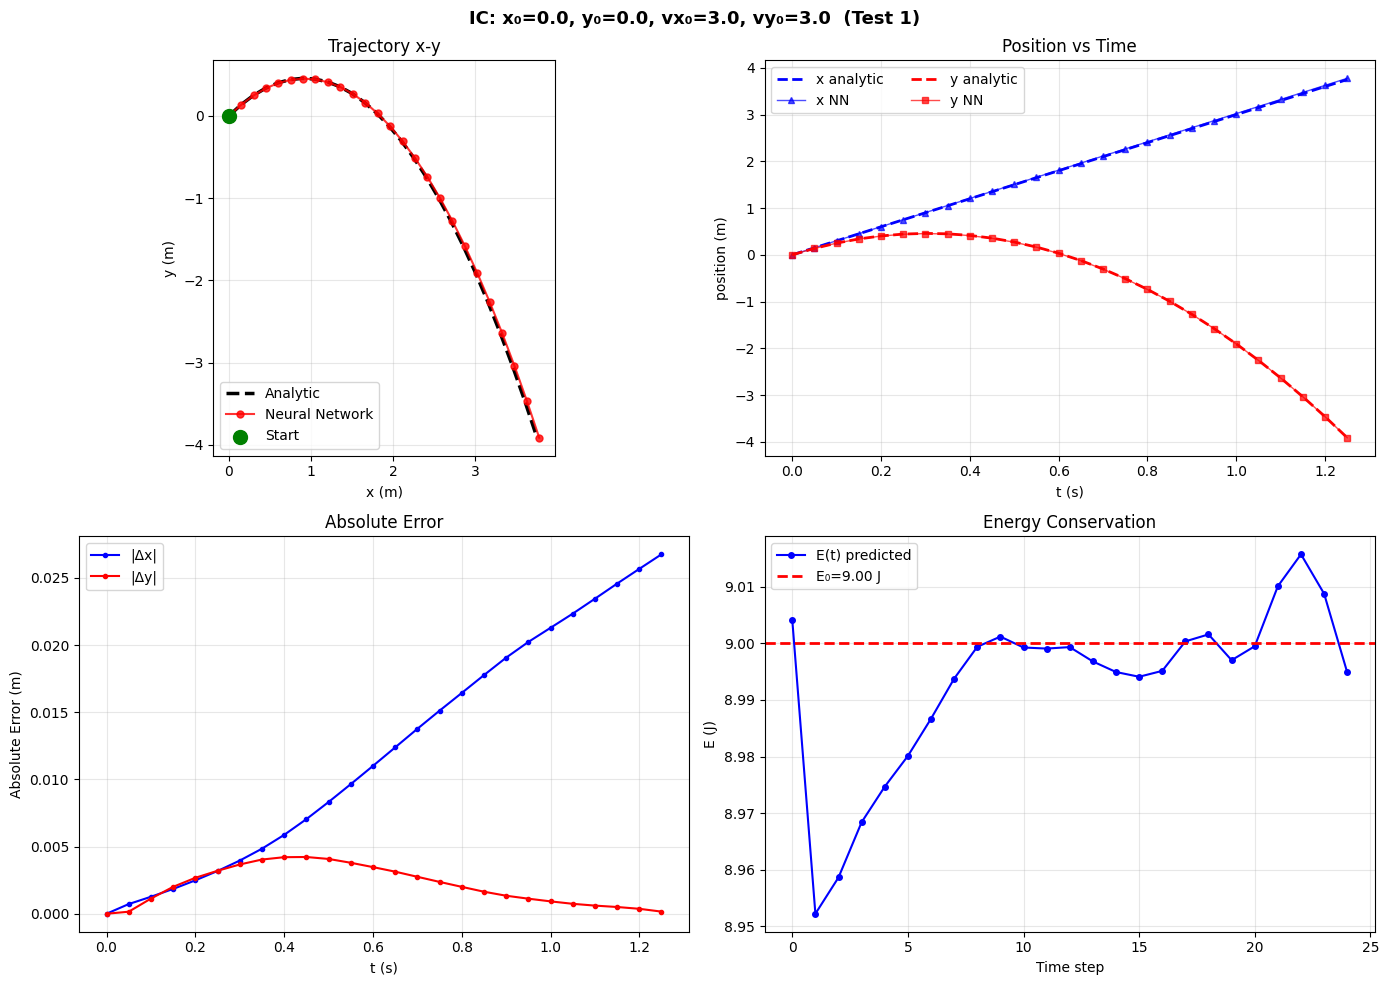

  RMSE_x=0.0150 m | RMSE_y=0.0025 m | σ(E)=0.0150 J


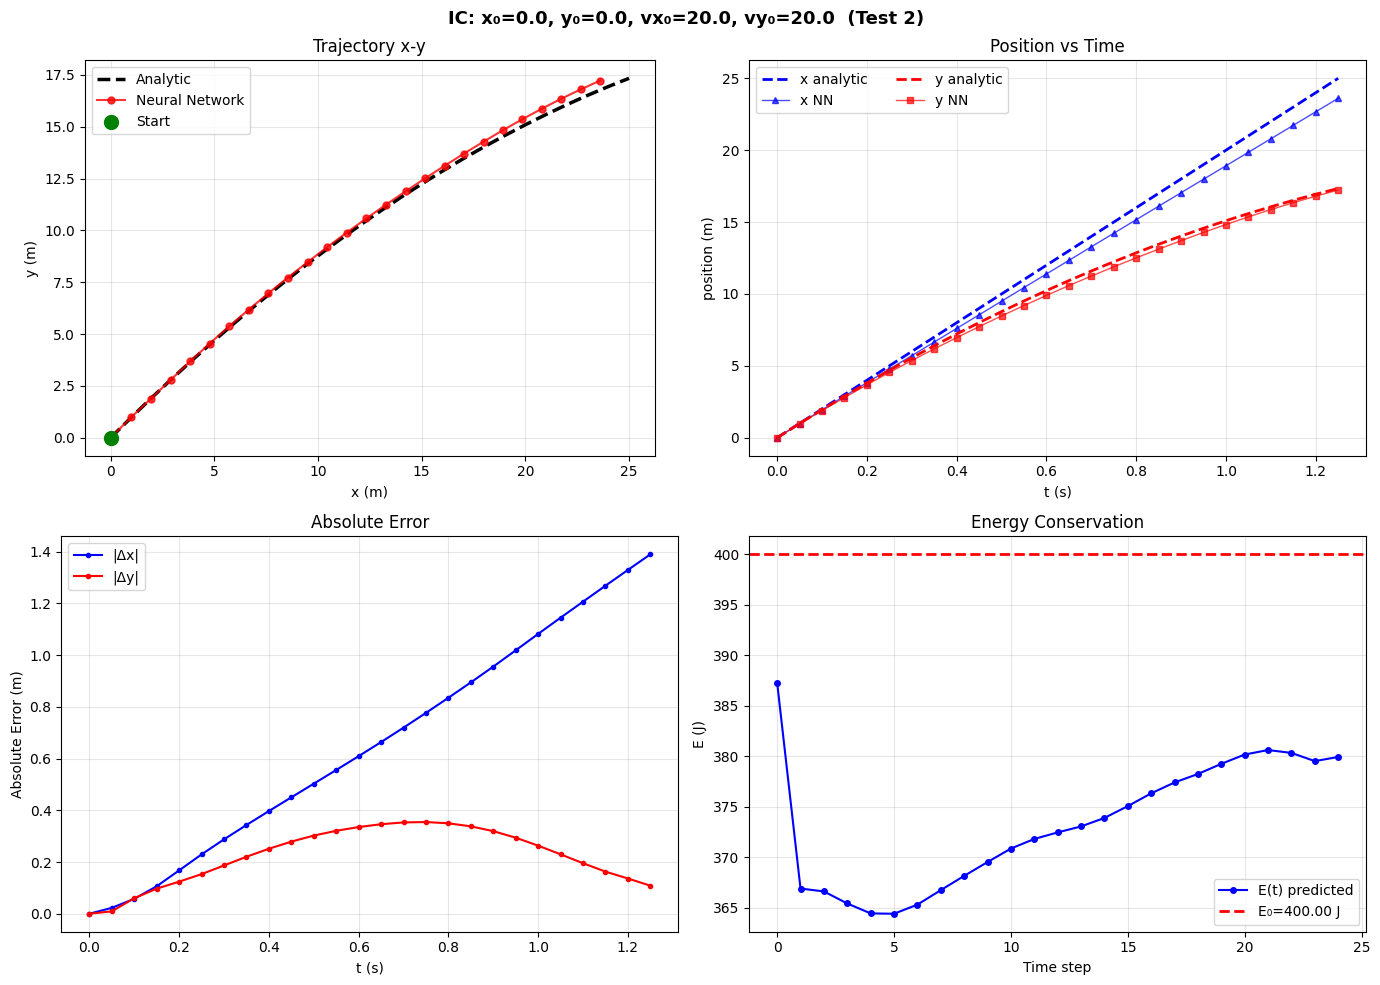

  RMSE_x=0.7807 m | RMSE_y=0.2477 m | σ(E)=6.2641 J


In [ ]:

test_conditions = np.array([
    [0.0, 0.0, 3, 3], # Inside the training domain 
    [0.0, 0.0, 20.0, 20.0], # Outside the training domain
], dtype=np.float32)

for i, ic in enumerate(test_conditions):
    plot_trajectory_comparison(model, ic, title_suffix=f"(Test {i+1})")

# Rollout Strategy


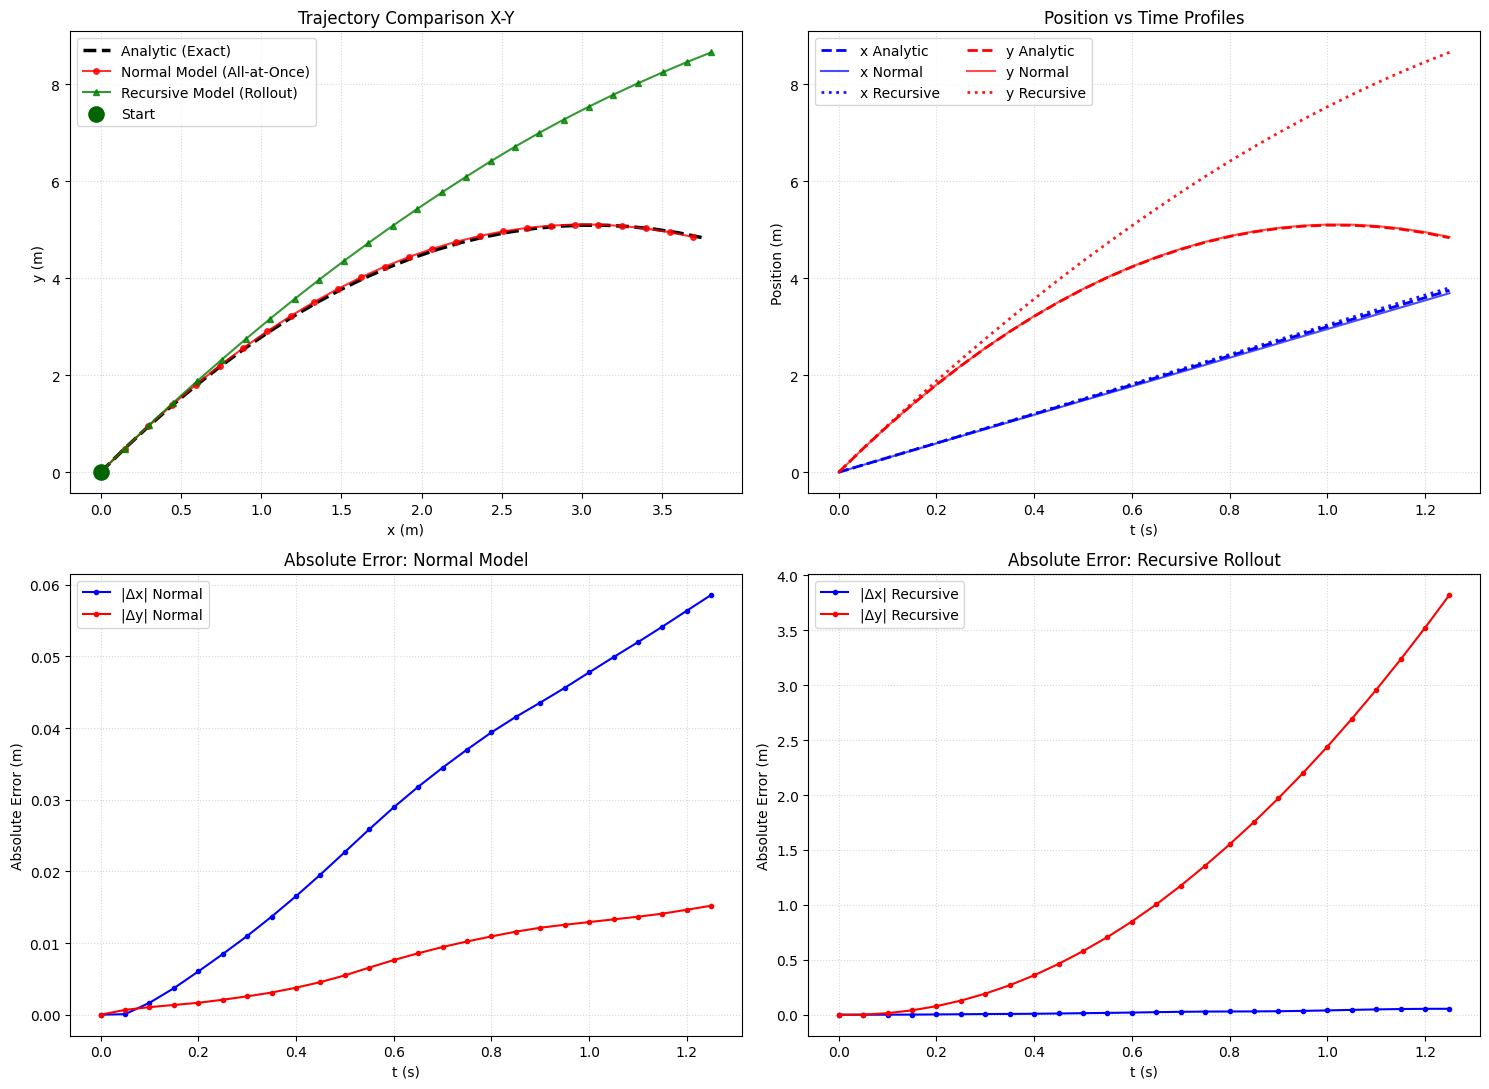

[ Normal ]    RMSE_x: 0.0345 m | RMSE_y: 0.0092 m
[ Recursive ] RMSE_x: 0.0288 m | RMSE_y: 1.7534 m


In [92]:

x0_init = 0.0
y0_init = 0.0
vx0_init = 3.0
vy0_init = 10.0

t_arr = np.arange(0, N + 1) * dt

x_an = x0_init + vx0_init * t_arr
y_an = y0_init + vy0_init * t_arr + 0.5 * g * (t_arr ** 2)

ic_normal = np.array([x0_init, y0_init, vx0_init, vy0_init], dtype=np.float32)
ic_t = torch.tensor(ic_normal, dtype=torch.float32).unsqueeze(0).to(device)

with torch.no_grad():
    pred_normal = model(ic_t).cpu().numpy()[0]

x_normal = np.concatenate([[x0_init], pred_normal[:N]])
y_normal = np.concatenate([[y0_init], pred_normal[N:]])

x_recursive = [x0_init]
y_recursive = [y0_init]

x0, y0, vx0, vy0 = x0_init, y0_init, vx0_init, vy0_init

for i in range(N):
    ic_step = np.array([[x0, y0, vx0, vy0]], dtype=np.float32)
    ic_step_t = torch.tensor(ic_step[0], dtype=torch.float32).unsqueeze(0).to(device)
    
    with torch.no_grad():
        pred_step = model(ic_step_t).cpu().numpy()[0]
        x_nn_local = np.concatenate([[x0], pred_step[:N]])
        y_nn_local = np.concatenate([[y0], pred_step[N:]])

        # Recalcular espacio de fase por diferencias finitas locales
        vx0 = (x_nn_local[1] - x_nn_local[0]) / dt
        vy0 = (y_nn_local[1] - y_nn_local[0]) / dt
        x0, y0 = x_nn_local[1], y_nn_local[1]
    
    x_recursive.append(x0)
    y_recursive.append(y0)

x_recursive = np.array(x_recursive)
y_recursive = np.array(y_recursive)

fig, axes = plt.subplots(2, 2, figsize=(15, 11))

ax = axes[0, 0]
ax.plot(x_an, y_an, 'k--', lw=2.5, label='Analytic (Exact)')
ax.plot(x_normal, y_normal, 'ro-', ms=4, lw=1.5, alpha=0.8, label='Normal Model (All-at-Once)')
ax.plot(x_recursive, y_recursive, 'g^-', ms=4, lw=1.5, alpha=0.8, label='Recursive Model (Rollout)')
ax.scatter([x0_init], [y0_init], c='darkgreen', s=120, zorder=10, label='Start')
ax.set_xlabel("x (m)")
ax.set_ylabel("y (m)")
ax.set_title("Trajectory Comparison X-Y")
ax.grid(True, linestyle=':', alpha=0.5)
ax.legend()

ax = axes[0, 1]
ax.plot(t_arr, x_an, 'b--', lw=2, label='x Analytic')
ax.plot(t_arr, x_normal, 'b-', alpha=0.7, label='x Normal')
ax.plot(t_arr, x_recursive, 'b:', alpha=0.9, lw=2, label='x Recursive')
ax.plot(t_arr, y_an, 'r--', lw=2, label='y Analytic')
ax.plot(t_arr, y_normal, 'r-', alpha=0.7, label='y Normal')
ax.plot(t_arr, y_recursive, 'r:', alpha=0.9, lw=2, label='y Recursive')
ax.set_xlabel("t (s)")
ax.set_ylabel("Position (m)")
ax.set_title("Position vs Time Profiles")
ax.grid(True, linestyle=':', alpha=0.5)
ax.legend(ncol=2)

ax = axes[1, 0]
ax.plot(t_arr, np.abs(x_normal - x_an), 'b.-', label='|Δx| Normal')
ax.plot(t_arr, np.abs(y_normal - y_an), 'r.-', label='|Δy| Normal')
ax.set_xlabel("t (s)")
ax.set_ylabel("Absolute Error (m)")
ax.set_title("Absolute Error: Normal Model")
ax.grid(True, linestyle=':', alpha=0.5)
ax.legend()

ax = axes[1, 1]
ax.plot(t_arr, np.abs(x_recursive - x_an), 'b.-', label='|Δx| Recursive')
ax.plot(t_arr, np.abs(y_recursive - y_an), 'r.-', label='|Δy| Recursive')
ax.set_xlabel("t (s)")
ax.set_ylabel("Absolute Error (m)")
ax.set_title("Absolute Error: Recursive Rollout")
ax.grid(True, linestyle=':', alpha=0.5)
ax.legend()

plt.tight_layout()
plt.show()

# Métricas globales de dispersión espacial
print(f"[ Normal ]    RMSE_x: {np.sqrt(np.mean((x_normal - x_an)**2)):.4f} m | RMSE_y: {np.sqrt(np.mean((y_normal - y_an)**2)):.4f} m")
print(f"[ Recursive ] RMSE_x: {np.sqrt(np.mean((x_recursive - x_an)**2)):.4f} m | RMSE_y: {np.sqrt(np.mean((y_recursive - y_an)**2)):.4f} m")